# MCU Data Analysis
**Milestone 1 – CIE:** Data Transformation, Null Value Handling, Insight Generation and Visualization

Dataset: Marvel Cinematic Universe (MCU) movies and TV series – ratings, budget and box office collection.

## 1. Dataset Selection and Reading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("mcu.csv")

In [3]:
df.head()

,movie_title,mcu_phase,release_date,tomato_meter,audience_score,movie_duration,production_budget,opening_weekend,domestic_box_office,worldwide_box_office
0,Iron Man,Phase 1,2008-05-02,94,91,126.0,140000000.0,102118668.0,319034126.0,585796247.0
1,The Incredible Hulk,Phase 1,2008-06-13,67,70,112.0,137500000.0,55414050.0,134806913.0,265573859.0
2,Iron Man 2,Phase 1,2010-05-07,72,71,124.0,200000000.0,128122480.0,312433331.0,621156389.0
3,Thor,Phase 1,2011-05-06,77,76,114.0,150000000.0,65723338.0,181030624.0,449326618.0
4,Captain America The First Avenger,Phase 1,2011-07-22,80,75,124.0,140000000.0,65058524.0,176654505.0,370569774.0


## 2. Data Understanding

In [4]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (62, 10)


In [5]:
df.columns

Index(['movie_title', 'mcu_phase', 'release_date', 'tomato_meter',
       'audience_score', 'movie_duration', 'production_budget',
       'opening_weekend', 'domestic_box_office', 'worldwide_box_office'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   movie_title           62 non-null     str    
 1   mcu_phase             62 non-null     str    
 2   release_date          62 non-null     str    
 3   tomato_meter          62 non-null     int64  
 4   audience_score        62 non-null     int64  
 5   movie_duration        38 non-null     float64
 6   production_budget     38 non-null     float64
 7   opening_weekend       38 non-null     float64
 8   domestic_box_office   38 non-null     float64
 9   worldwide_box_office  38 non-null     float64
dtypes: float64(5), int64(2), str(3)
memory usage: 5.0 KB


In [7]:
df.describe()

,tomato_meter,audience_score,movie_duration,production_budget,opening_weekend,domestic_box_office,worldwide_box_office
count,62.000000,62.000000,38.000000,3.800000e+01,3.800000e+01,3.800000e+01,3.800000e+01
mean,82.629032,81.209677,130.868421,2.034605e+08,1.377335e+08,3.671251e+08,9.137550e+08
std,12.715337,14.044586,15.518378,5.559924e+07,7.728089e+07,2.054218e+08,5.823871e+08
min,46.000000,32.000000,105.000000,1.300000e+08,4.611086e+07,8.450022e+07,2.061368e+08
25%,77.000000,76.250000,118.750000,1.700000e+08,8.156431e+07,2.083978e+08,4.868814e+08
50%,86.000000,86.000000,128.500000,2.000000e+08,1.173362e+08,3.261054e+08,7.671391e+08
75%,91.750000,91.000000,136.000000,2.237500e+08,1.807896e+08,4.229553e+08,1.147956e+09
max,99.000000,98.000000,181.000000,3.650000e+08,3.600916e+08,8.584002e+08,2.799439e+09


In [8]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [9]:
df['mcu_phase'].value_counts()

mcu_phase
Phase 5    17
Phase 4    15
Phase 3    11
Phase 6     7
Phase 1     6
Phase 2     6
Name: count, dtype: int64

## 3. Data Transformation

**Changing data type:** `release_date` is stored as text, so it is converted to datetime.

In [10]:
df['release_date'] = pd.to_datetime(df['release_date'])

print(df['release_date'].dtype)

datetime64[us]


**Adding a new column:** `content_type`. Rows that have no box office data are TV series (they never had a theatrical release). This column is created *before* null handling so that we can still tell movies and TV series apart later.

In [11]:
df['content_type'] = np.where(df['worldwide_box_office'].isnull(), 'TV Series', 'Movie')

print(df['content_type'].value_counts())

content_type
Movie        38
TV Series    24
Name: count, dtype: int64


**Adding new columns:** release year and release month, extracted from the date.

In [12]:
df['release_year'] = df['release_date'].dt.year
df['release_month'] = df['release_date'].dt.month

print(df[['movie_title', 'release_date', 'release_year', 'release_month']].head())

                         movie_title release_date  release_year  release_month
0                           Iron Man   2008-05-02          2008              5
1                The Incredible Hulk   2008-06-13          2008              6
2                         Iron Man 2   2010-05-07          2010              5
3                               Thor   2011-05-06          2011              5
4  Captain America The First Avenger   2011-07-22          2011              7


**Dropping an unnecessary column:** once the year and month are extracted, the full `release_date` is no longer needed.

In [13]:
df = df.drop(columns=['release_date'])

print("Column removed successfully!")
print(df.columns.tolist())

Column removed successfully!
['movie_title', 'mcu_phase', 'tomato_meter', 'audience_score', 'movie_duration', 'production_budget', 'opening_weekend', 'domestic_box_office', 'worldwide_box_office', 'content_type', 'release_year', 'release_month']


**Adding new columns:** amounts in millions of dollars to make the numbers easier to read, and a rating difference column.

In [14]:
df['budget_million'] = df['production_budget'] / 1000000
df['opening_million'] = df['opening_weekend'] / 1000000
df['domestic_million'] = df['domestic_box_office'] / 1000000
df['worldwide_million'] = df['worldwide_box_office'] / 1000000

df['rating_gap'] = df['audience_score'] - df['tomato_meter']

print(df[['movie_title', 'worldwide_box_office', 'worldwide_million']].head())

                         movie_title  worldwide_box_office  worldwide_million
0                           Iron Man           585796247.0         585.796247
1                The Incredible Hulk           265573859.0         265.573859
2                         Iron Man 2           621156389.0         621.156389
3                               Thor           449326618.0         449.326618
4  Captain America The First Avenger           370569774.0         370.569774


## 4. Handling Null Values

In [15]:
df.isnull().sum()

movie_title              0
mcu_phase                0
tomato_meter             0
audience_score           0
movie_duration          24
production_budget       24
opening_weekend         24
domestic_box_office     24
worldwide_box_office    24
content_type             0
release_year             0
release_month            0
budget_million          24
opening_million         24
domestic_million        24
worldwide_million       24
rating_gap               0
dtype: int64

All the nulls are in the movie-only columns (duration, budget and box office). The 24 null rows are the TV series. Mean imputation is applied to the numerical columns as required by the milestone.

In [16]:
numeric_cols = df.select_dtypes(include='number').columns

df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].mean()
)

print("Mean imputation completed!")
print(df.isnull().sum())

Mean imputation completed!
movie_title             0
mcu_phase               0
tomato_meter            0
audience_score          0
movie_duration          0
production_budget       0
opening_weekend         0
domestic_box_office     0
worldwide_box_office    0
content_type            0
release_year            0
release_month           0
budget_million          0
opening_million         0
domestic_million        0
worldwide_million       0
rating_gap              0
dtype: int64


`rating_gap` has no nulls, but the derived columns *profit* and *ROI* are created now, after the missing values are filled.

In [17]:
df['profit_million'] = df['worldwide_million'] - df['budget_million']
df['roi'] = df['profit_million'] / df['budget_million']

df[['movie_title', 'budget_million', 'worldwide_million', 'profit_million', 'roi']].head()

,movie_title,budget_million,worldwide_million,profit_million,roi
0,Iron Man,140.0,585.796247,445.796247,3.184259
1,The Incredible Hulk,137.5,265.573859,128.073859,0.931446
2,Iron Man 2,200.0,621.156389,421.156389,2.105782
3,Thor,150.0,449.326618,299.326618,1.995511
4,Captain America The First Avenger,140.0,370.569774,230.569774,1.646927


> **Note:** the imputed values belong to TV series, which have no real box office. To avoid mixing these artificial averages into the results, the box-office insights below are generated for `content_type == 'Movie'` only. Ratings are available for every title, so they are analysed for both movies and TV series.

In [18]:
movies = df[df['content_type'] == 'Movie']

print("Movies:", movies.shape[0])
print("TV Series:", (df['content_type'] == 'TV Series').sum())

Movies: 38
TV Series: 24


## 5. Insight Generation

### Top 10 movies by worldwide box office

In [19]:
top10 = movies.sort_values(by='worldwide_million', ascending=False)

print(top10[['movie_title', 'worldwide_million']].head(10))

                  movie_title  worldwide_million
21           Avengers Endgame        2799.439100
37   Spider-Man Brand New Day        2224.515513
18      Avengers Infinity War        2052.415039
26     Spider-Man No Way Home        1922.560366
5                The Avengers        1518.812988
10     Avengers Age of Ultron        1395.316979
17              Black Panther        1353.282444
33       Deadpool & Wolverine        1338.073645
6                  Iron Man 3        1214.811252
12  Captain America Civil War        1153.296293


### Average ratings and box office

In [20]:
print("Average Tomatometer Score:", round(df['tomato_meter'].mean(), 2))
print("Average Audience Score:", round(df['audience_score'].mean(), 2))
print("Average Worldwide Box Office (Million $):", round(movies['worldwide_million'].mean(), 2))
print("Average Production Budget (Million $):", round(movies['budget_million'].mean(), 2))

Average Tomatometer Score: 82.63
Average Audience Score: 81.21
Average Worldwide Box Office (Million $): 913.75
Average Production Budget (Million $): 203.46


### Phase-wise performance of the movies

In [21]:
phase_stats = movies.groupby('mcu_phase')[['budget_million', 'worldwide_million', 'profit_million', 'tomato_meter', 'audience_score']].mean().round(2)

print(phase_stats)

           budget_million  worldwide_million  profit_million  tomato_meter  \
mcu_phase                                                                    
Phase 1            164.58             635.21          470.62         80.17   
Phase 2            200.83             876.97          676.14         80.83   
Phase 3            213.45            1229.76         1016.31         89.18   
Phase 4            212.29             816.08          603.79         75.86   
Phase 5            213.33             610.56          397.23         67.17   
Phase 6            212.50            1373.19         1160.69         87.50   

           audience_score  
mcu_phase                  
Phase 1             79.00  
Phase 2             84.00  
Phase 3             83.27  
Phase 4             88.43  
Phase 5             86.50  
Phase 6             91.50  


### Most profitable movies (highest ROI)

In [22]:
top_roi = movies.nlargest(10, 'roi')

print(top_roi[['movie_title', 'budget_million', 'worldwide_million', 'roi']])

                 movie_title  budget_million  worldwide_million       roi
37  Spider-Man Brand New Day           225.0        2224.515513  8.886736
26    Spider-Man No Way Home           200.0        1922.560366  8.612802
21          Avengers Endgame           356.0        2799.439100  6.863593
22  Spider-Man Far From Home           160.0        1131.927996  6.074550
5               The Avengers           220.0        1518.812988  5.903695
17             Black Panther           200.0        1353.282444  5.766412
33      Deadpool & Wolverine           200.0        1338.073645  5.690368
20            Captain Marvel           175.0        1131.934225  5.468196
18     Avengers Infinity War           325.0        2052.415039  5.315123
6                 Iron Man 3           200.0        1214.811252  5.074056


### Movies vs TV series ratings

In [23]:
type_ratings = df.groupby('content_type')[['tomato_meter', 'audience_score']].mean().round(2)

print(type_ratings)

              tomato_meter  audience_score
content_type                              
Movie                80.42           84.61
TV Series            86.12           75.83


### Best and worst rated titles

In [24]:
print("Highest Tomatometer:")
print(df.nlargest(5, 'tomato_meter')[['movie_title', 'tomato_meter']])

print("\nLowest Tomatometer:")
print(df.nsmallest(5, 'tomato_meter')[['movie_title', 'tomato_meter']])

Highest Tomatometer:
                              movie_title  tomato_meter
50                              X-Men '97            99
44                             Ms. Marvel            98
52  Your Friendly Neighborhood Spider-Man            97
17                          Black Panther            96
61                     X-Men '97 Season 2            96

Lowest Tomatometer:
                         movie_title  tomato_meter
30  Ant-Man and the Wasp Quantumania            46
25                          Eternals            47
34   Captain America Brave New World            48
46                   Secret Invasion            53
32                       The Marvels            62


### Correlation between budget, box office and ratings

In [25]:
corr_cols = ['budget_million', 'opening_million', 'worldwide_million', 'tomato_meter', 'audience_score']

print(movies[corr_cols].corr().round(2))

                   budget_million  opening_million  worldwide_million  \
budget_million               1.00             0.61               0.59   
opening_million              0.61             1.00               0.95   
worldwide_million            0.59             0.95               1.00   
tomato_meter                -0.07             0.33               0.43   
audience_score               0.15             0.25               0.26   

                   tomato_meter  audience_score  
budget_million            -0.07            0.15  
opening_million            0.33            0.25  
worldwide_million          0.43            0.26  
tomato_meter               1.00            0.47  
audience_score             0.47            1.00  


### Movies released and total box office per year

In [26]:
yearly = movies.groupby('release_year').agg(
    movies_released=('movie_title', 'count'),
    total_worldwide=('worldwide_million', 'sum')
)

print(yearly.round(2))

              movies_released  total_worldwide
release_year                                  
2008                        2           851.37
2010                        1           621.16
2011                        2           819.90
2012                        1          1518.81
2013                        2          1859.41
2014                        2          1487.77
2015                        2          1914.63
2016                        2          1831.09
2017                        3          2604.59
2018                        3          4028.37
2019                        3          5063.30
2021                        4          3136.62
2022                        3          2575.91
2023                        3          1527.76
2024                        1          1338.07
2025                        3          1319.40
2026                        1          2224.52


## 6. Data Visualization

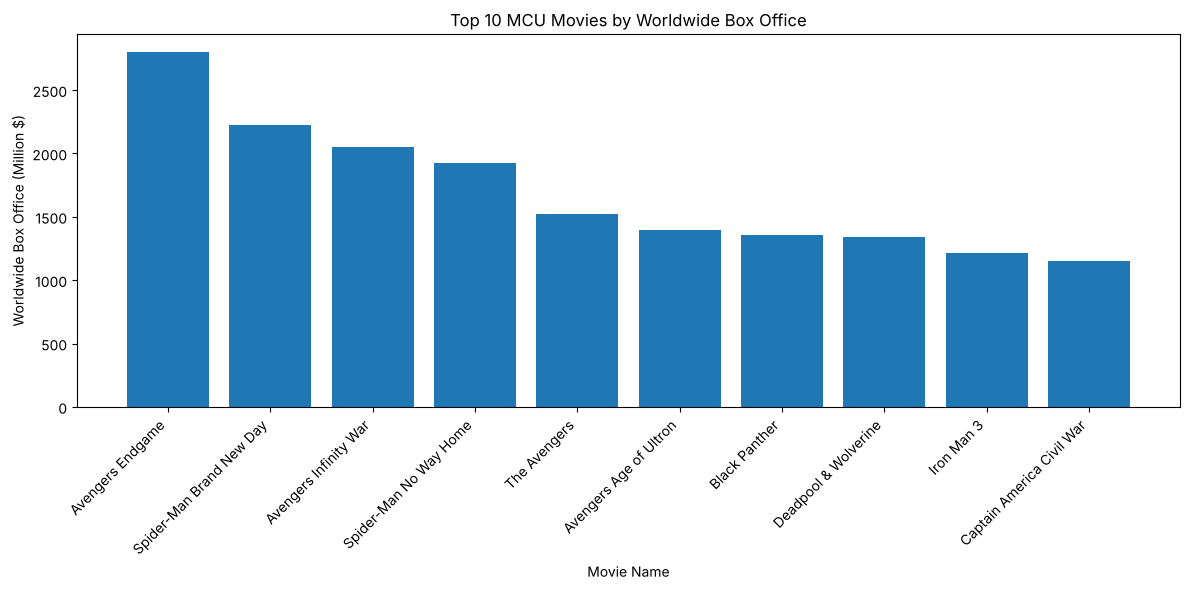

In [27]:
top10 = movies.nlargest(10, 'worldwide_million')

plt.figure(figsize=(12, 6))

plt.bar(top10['movie_title'], top10['worldwide_million'])

plt.title('Top 10 MCU Movies by Worldwide Box Office')
plt.xlabel('Movie Name')
plt.ylabel('Worldwide Box Office (Million $)')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

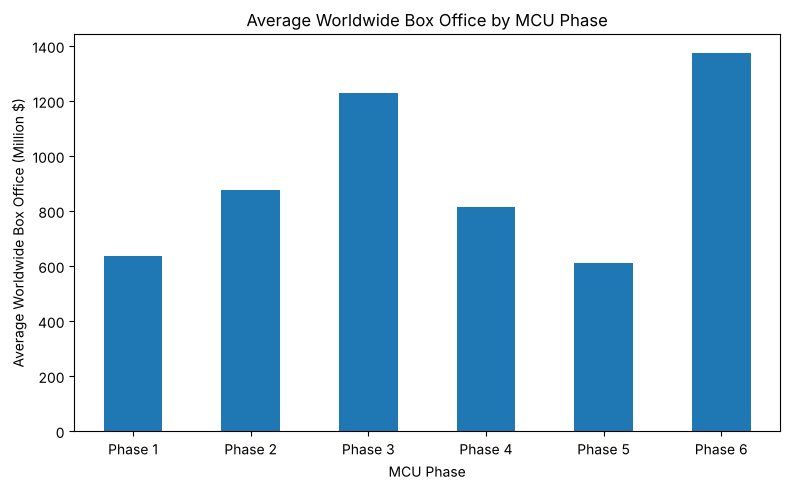

In [28]:
plt.figure(figsize=(8, 5))

phase_stats['worldwide_million'].plot(kind='bar')

plt.title('Average Worldwide Box Office by MCU Phase')
plt.xlabel('MCU Phase')
plt.ylabel('Average Worldwide Box Office (Million $)')

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

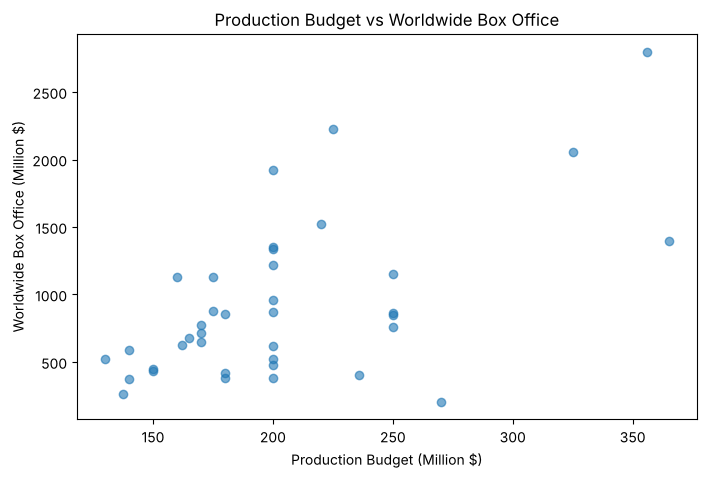

In [29]:
plt.figure(figsize=(8, 5))

plt.scatter(movies['budget_million'], movies['worldwide_million'], alpha=0.6)

plt.title('Production Budget vs Worldwide Box Office')
plt.xlabel('Production Budget (Million $)')
plt.ylabel('Worldwide Box Office (Million $)')

plt.show()

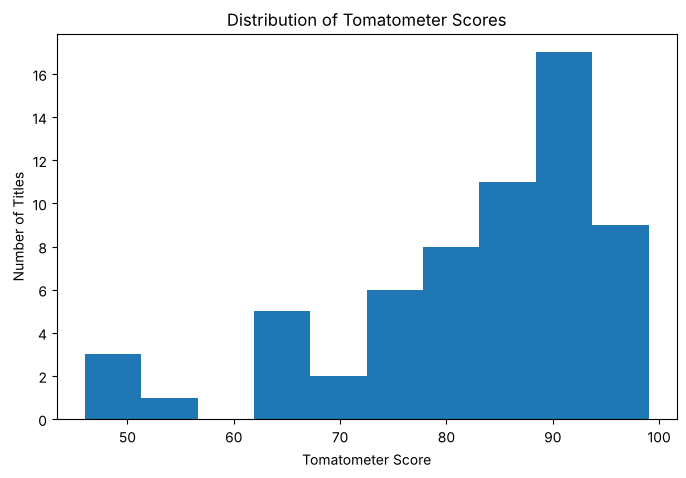

In [30]:
plt.figure(figsize=(8, 5))

plt.hist(df['tomato_meter'], bins=10)

plt.title('Distribution of Tomatometer Scores')
plt.xlabel('Tomatometer Score')
plt.ylabel('Number of Titles')

plt.show()

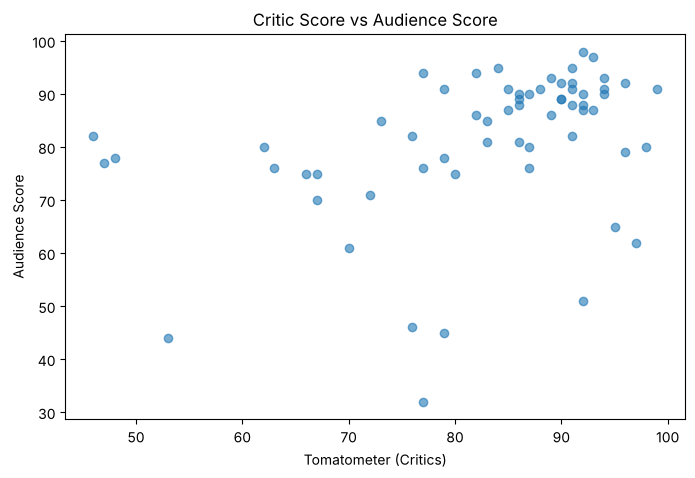

In [31]:
plt.figure(figsize=(8, 5))

plt.scatter(df['tomato_meter'], df['audience_score'], alpha=0.6)

plt.title('Critic Score vs Audience Score')
plt.xlabel('Tomatometer (Critics)')
plt.ylabel('Audience Score')

plt.show()

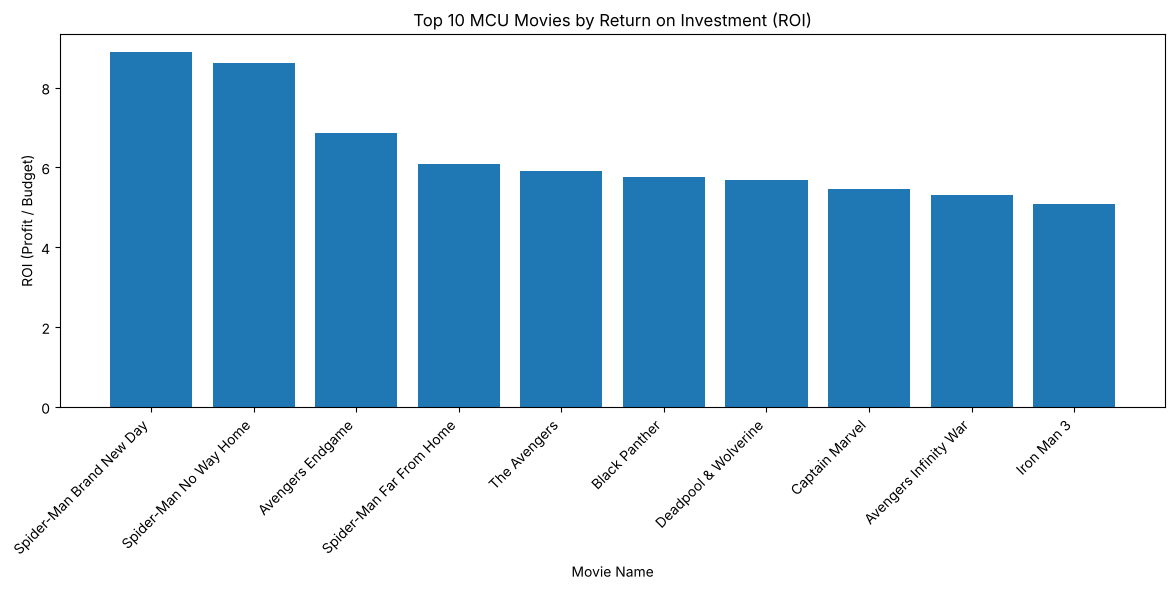

In [32]:
top_roi = movies.nlargest(10, 'roi')

plt.figure(figsize=(12, 6))

plt.bar(top_roi['movie_title'], top_roi['roi'])

plt.title('Top 10 MCU Movies by Return on Investment (ROI)')
plt.xlabel('Movie Name')
plt.ylabel('ROI (Profit / Budget)')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

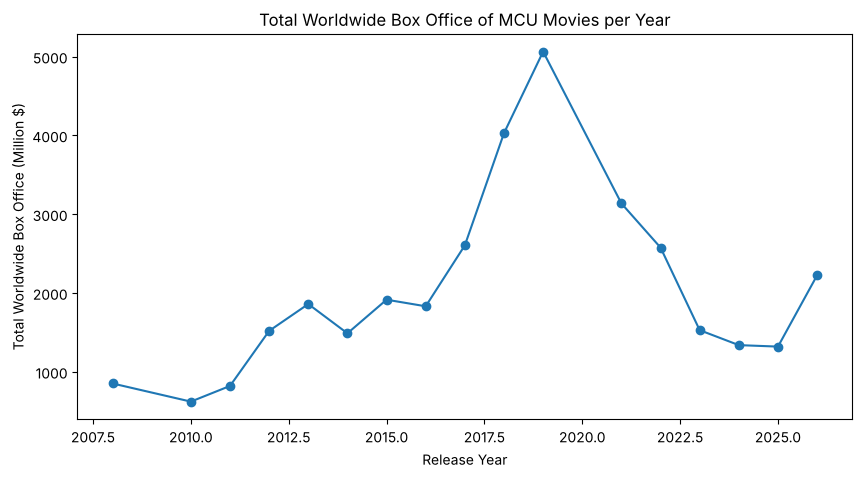

In [33]:
plt.figure(figsize=(10, 5))

plt.plot(yearly.index, yearly['total_worldwide'], marker='o')

plt.title('Total Worldwide Box Office of MCU Movies per Year')
plt.xlabel('Release Year')
plt.ylabel('Total Worldwide Box Office (Million $)')

plt.show()

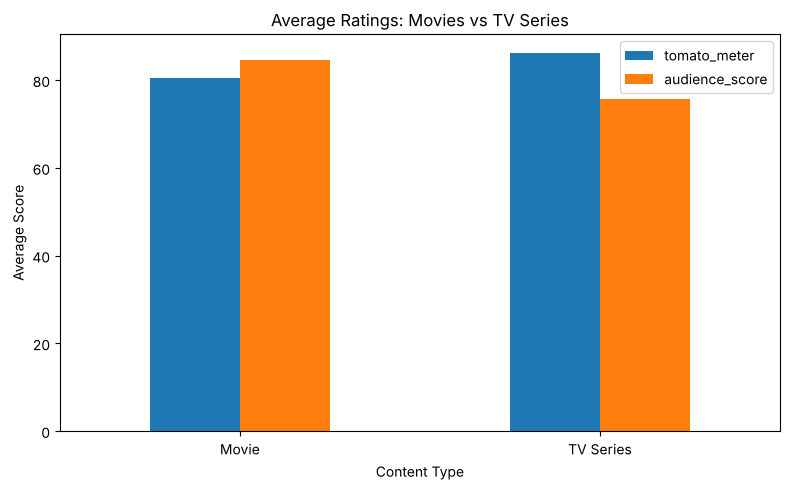

In [34]:
type_ratings.plot(kind='bar', figsize=(8, 5))

plt.title('Average Ratings: Movies vs TV Series')
plt.xlabel('Content Type')
plt.ylabel('Average Score')

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

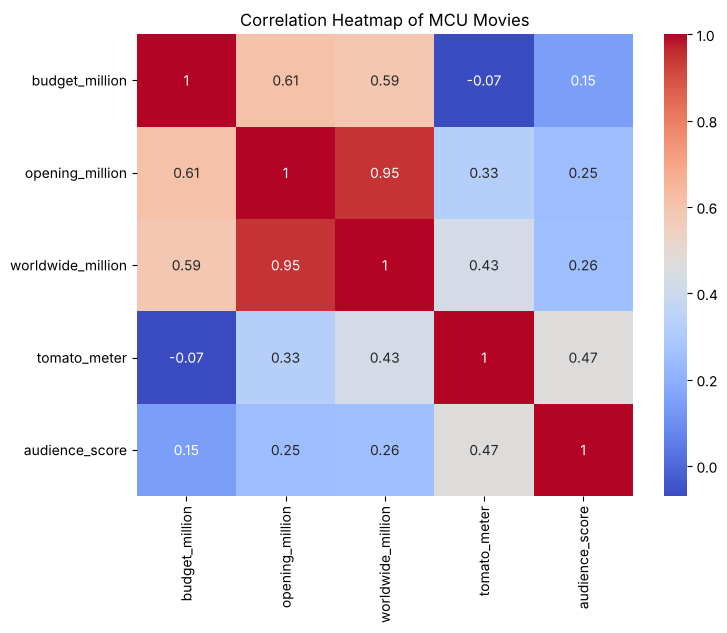

In [35]:
plt.figure(figsize=(8, 6))

sns.heatmap(movies[corr_cols].corr(), annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap of MCU Movies')

plt.show()

## Conclusion

This project analyzed Marvel Cinematic Universe (MCU) data using Python and Pandas.

Data transformation was performed by changing data types, adding new columns (content type, release year, ROI, etc.) and dropping an unnecessary column. Null values were identified and handled using mean imputation. Since the nulls belonged to TV series, the box office insights were generated for movies only.

Meaningful insights were generated about the highest-grossing movies, phase-wise performance, return on investment, and the relationship between budget, box office and ratings.

Visualizations were created using Matplotlib and Seaborn to communicate the findings.

This project provided practical experience in data analysis, data transformation, null value handling, and visualization.